In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

from sklearn.model_selection import train_test_split, KFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import xgboost as xgb
import shap

%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 120

PROJECT_ROOT = Path("/mnt/d/IDC409_Project15")
FIGURES_DIR  = PROJECT_ROOT / "reports" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
engine = create_engine(f"sqlite:///{PROJECT_ROOT / 'data' / 'processed' / 'house_prices.db'}")

# Reload and re-prepare Ames data
# (same steps as Phase 5 — we need the same X_train, X_test, y_train, y_test)
df = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "ames_housing" / "train.csv")

TARGET = 'SalePrice'
y = df[TARGET].copy()
X = df.drop(columns=[TARGET]).copy()

# Drop high-missing columns and Id
missing_pct = X.isnull().mean() * 100
high_missing = missing_pct[missing_pct > 40].index.tolist()
X = X.drop(columns=['Id'] + high_missing)

# Impute
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

X[num_cols] = SimpleImputer(strategy='median').fit_transform(X[num_cols])
X[cat_cols] = SimpleImputer(strategy='constant', fill_value='Unknown').fit_transform(X[cat_cols])

# Encode
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
bool_cols  = X_encoded.select_dtypes(include='bool').columns
X_encoded[bool_cols] = X_encoded[bool_cols].astype(int)

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42
)

print(f"Data ready: {X_train.shape[0]} train / {X_test.shape[0]} test rows")
print(f"Features: {X_train.shape[1]} columns")

Data ready: 1168 train / 292 test rows
Features: 239 columns


/tmp/ipykernel_5189/3854156333.py:40: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include='object').columns.tolist()


In [2]:
# XGBoost = eXtreme Gradient Boosting
#
# Random Forest builds trees IN PARALLEL — each tree is independent,
# then we average their predictions.
#
# XGBoost builds trees IN SEQUENCE — each new tree specifically focuses
# on the mistakes the previous trees made. It's like a team where each
# new member studies where the previous members went wrong.
#
# Result: XGBoost almost always outperforms Random Forest on tabular data.
# It's the most used algorithm in winning Kaggle competition submissions.

xgb_model = xgb.XGBRegressor(
    n_estimators=300,      # number of trees
    learning_rate=0.05,    # how much each tree corrects the previous ones
                           # lower = slower learning but more precise
    max_depth=4,           # depth of each tree — kept shallow to avoid overfitting
    subsample=0.8,         # each tree sees 80% of training rows (adds randomness)
    colsample_bytree=0.8,  # each tree sees 80% of features (adds randomness)
    random_state=42,
    verbosity=0            # suppress output during training
)

xgb_model.fit(X_train, y_train)
y_pred_xgb = xgb_model.predict(X_test)

mae_xgb  = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))
r2_xgb   = r2_score(y_test, y_pred_xgb)

print("XGBoost Results:")
print(f"  MAE  : ${mae_xgb:>10,.0f}")
print(f"  RMSE : ${rmse_xgb:>10,.0f}")
print(f"  R²   :  {r2_xgb:>10.4f}")
print(f"\nVs Random Forest (Phase 5):")
print(f"  RF  R² = 0.8918, MAE = $17,573")
print(f"  XGB R² = {r2_xgb:.4f}, MAE = ${mae_xgb:,.0f}")
print(f"\nImprovement: R² {'improved' if r2_xgb > 0.8918 else 'similar'}")

XGBoost Results:
  MAE  : $    15,331
  RMSE : $    25,045
  R²   :      0.9182

Vs Random Forest (Phase 5):
  RF  R² = 0.8918, MAE = $17,573
  XGB R² = 0.9182, MAE = $15,331

Improvement: R² improved


In [3]:
# Every model has settings called "hyperparameters" — things you choose
# before training, like how many trees or how deep they go.
# 
# RandomizedSearchCV automatically tries many combinations and finds
# the best one using cross-validation. It's smarter than guessing by hand.
#
# We tune Random Forest here because it's more interpretable than XGBoost
# and the tuning concept is the same for any model.

print("Tuning Random Forest hyperparameters...")
print("This will take 1-2 minutes — running 20 combinations × 3 folds = 60 fits\n")

param_grid = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'max_features':      ['sqrt', 'log2', 0.5],
}

rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# n_iter=20: tries 20 random combinations from the grid
# cv=3: 3-fold cross validation for each combination
# scoring='r2': picks the combo with best R²
search = RandomizedSearchCV(
    rf_base,
    param_distributions=param_grid,
    n_iter=20,
    cv=3,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print(f"\nBest hyperparameters found:")
for param, value in search.best_params_.items():
    print(f"  {param:<22} : {value}")

print(f"\nBest CV R² during search: {search.best_score_:.4f}")

Tuning Random Forest hyperparameters...
This will take 1-2 minutes — running 20 combinations × 3 folds = 60 fits

Fitting 3 folds for each of 20 candidates, totalling 60 fits

Best hyperparameters found:
  n_estimators           : 500
  min_samples_split      : 2
  min_samples_leaf       : 2
  max_features           : 0.5
  max_depth              : 10

Best CV R² during search: 0.8589


In [4]:
best_rf = search.best_estimator_

y_pred_tuned = best_rf.predict(X_test)
mae_tuned    = mean_absolute_error(y_test, y_pred_tuned)
rmse_tuned   = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
r2_tuned     = r2_score(y_test, y_pred_tuned)

print("Tuned Random Forest vs Default Random Forest:\n")
print(f"{'Metric':<8} {'Default RF':>15} {'Tuned RF':>15} {'Change':>10}")
print("-" * 52)
print(f"{'MAE':<8} {'$17,573':>15} ${mae_tuned:>13,.0f}   "
      f"{'▼ better' if mae_tuned < 17573 else '▲ worse'}")
print(f"{'R²':<8} {'0.8918':>15} {r2_tuned:>15.4f}   "
      f"{'▲ better' if r2_tuned > 0.8918 else '▼ similar'}")

Tuned Random Forest vs Default Random Forest:

Metric        Default RF        Tuned RF     Change
----------------------------------------------------
MAE              $17,573 $       17,202   ▼ better
R²                0.8918          0.8943   ▲ better


In [5]:
# SHAP = SHapley Additive exPlanations
#
# The problem with complex models: they're black boxes.
# Random Forest with 300 trees — how does it decide a house is worth $250k?
#
# SHAP solves this. For every prediction on every house, it calculates
# how much each feature PUSHED the prediction up or down from the average.
#
# Example output: "This house was predicted at $280k because:
#   + OverallQual = 8   pushed price UP by $45,000
#   + GrLivArea = 2000  pushed price UP by $22,000
#   - YearBuilt = 1965  pushed price DOWN by $8,000"
#
# This is industry-standard ML explainability.

print("Calculating SHAP values (this takes about 30-60 seconds)...")

explainer   = shap.TreeExplainer(best_rf)
shap_values = explainer.shap_values(X_test)

print(f"SHAP values calculated for {X_test.shape[0]} houses × {X_test.shape[1]} features")
print("Shape of SHAP values array:", np.array(shap_values).shape)

Calculating SHAP values (this takes about 30-60 seconds)...
SHAP values calculated for 292 houses × 239 features
Shape of SHAP values array: (292, 239)


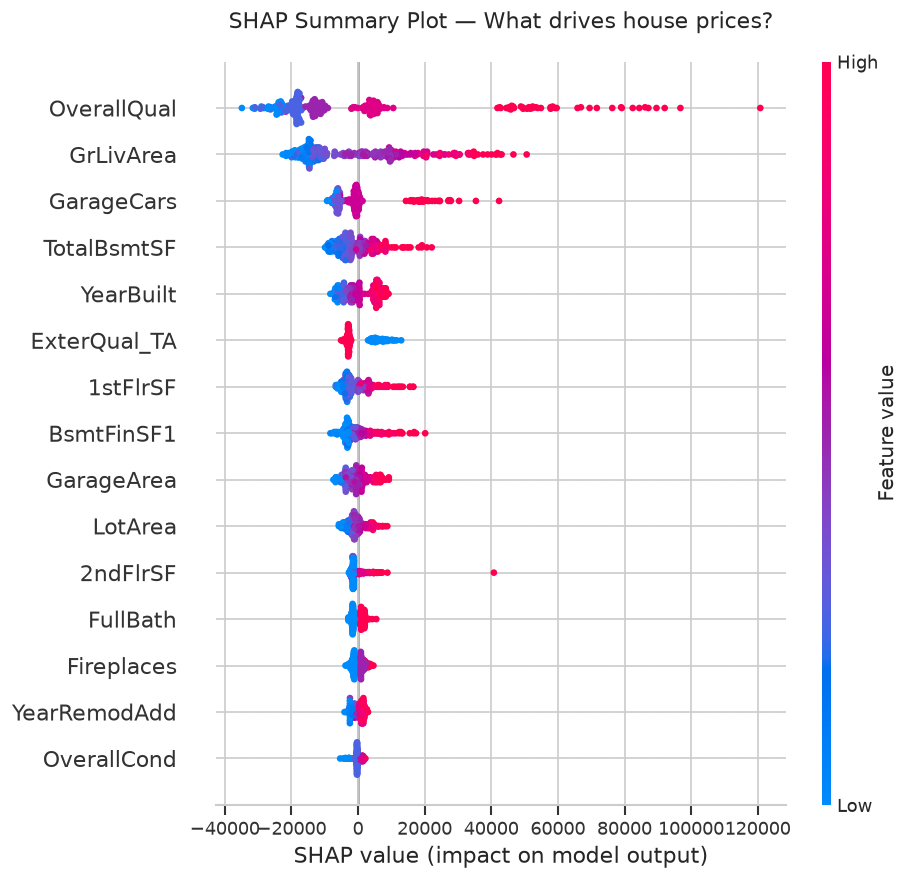

Saved: shap_summary_plot.png

How to read this:
  • Each row = one feature (sorted by importance)
  • Each dot = one house
  • Right of centre = pushed price UP
  • Left of centre  = pushed price DOWN
  • Red dot = high feature value, Blue dot = low feature value


In [6]:
# The SHAP summary plot is the most informative plot in the whole project.
# 
# Each row = one feature
# Each dot = one house in the test set
# Position left/right = how much it pushed the prediction down/up
# Color = the feature's actual value (red = high, blue = low)
#
# Read it like: "Red dots for OverallQual on the right side" means
# "houses with HIGH overall quality got their price pushed UP" — makes sense!

plt.figure(figsize=(10, 8))
shap.summary_plot(
    shap_values,
    X_test,
    max_display=15,        # show top 15 features
    show=False             # don't auto-show — let us save it first
)
plt.title("SHAP Summary Plot — What drives house prices?", 
          fontsize=13, pad=20)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_summary_plot.png", bbox_inches='tight')
plt.show()
print("Saved: shap_summary_plot.png")
print("\nHow to read this:")
print("  • Each row = one feature (sorted by importance)")
print("  • Each dot = one house")
print("  • Right of centre = pushed price UP")
print("  • Left of centre  = pushed price DOWN")
print("  • Red dot = high feature value, Blue dot = low feature value")

Explaining prediction for house #32
  Actual price    : $200,500
  Predicted price : $185,886
  Error           : $14,614


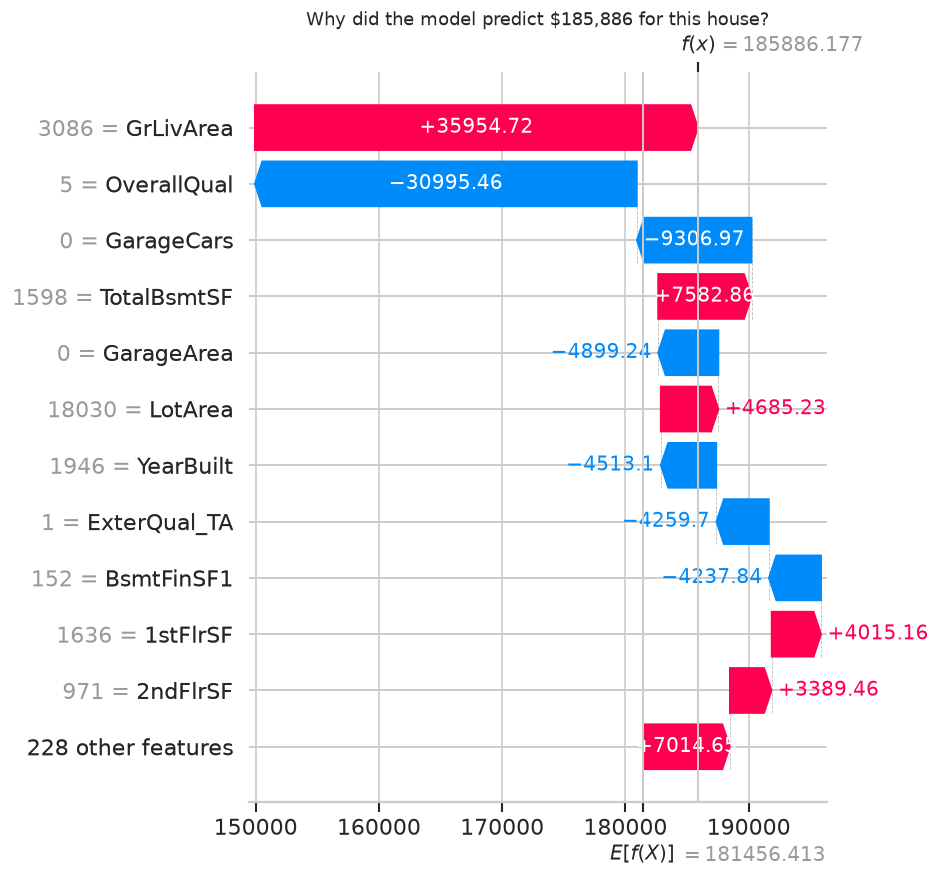

Saved: shap_waterfall_single_house.png


In [8]:
# Fix: extract scalar from expected_value before building the Explanation object
base_val = float(np.array(explainer.expected_value).ravel()[0])

# Pick the house closest to $200k
target_price = 200000
house_idx = (np.abs(y_test.values - target_price)).argmin()
actual_price    = y_test.values[house_idx]
predicted_price = y_pred_tuned[house_idx]

print(f"Explaining prediction for house #{house_idx}")
print(f"  Actual price    : ${actual_price:,.0f}")
print(f"  Predicted price : ${predicted_price:,.0f}")
print(f"  Error           : ${abs(actual_price - predicted_price):,.0f}")

explanation = shap.Explanation(
    values        = shap_values[house_idx],
    base_values   = base_val,
    data          = X_test.iloc[house_idx].values,
    feature_names = X_test.columns.tolist()
)

plt.figure(figsize=(10, 6))
shap.waterfall_plot(explanation, max_display=12, show=False)
plt.title(f"Why did the model predict ${predicted_price:,.0f} for this house?",
          fontsize=11)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "shap_waterfall_single_house.png", bbox_inches='tight')
plt.show()
print("Saved: shap_waterfall_single_house.png")

In [9]:
final_results = pd.DataFrame([
    {'Model': 'Baseline (mean)',          'MAE': 62576,      'RMSE': 87619,     'R²': -0.0009},
    {'Model': 'Ridge Regression',         'MAE': 19332,      'RMSE': 37400,     'R²': 0.8176},
    {'Model': 'Lasso Regression',         'MAE': 19346,      'RMSE': 44984,     'R²': 0.7362},
    {'Model': 'Decision Tree (depth=8)',  'MAE': 27331,      'RMSE': 43370,     'R²': 0.7548},
    {'Model': 'Random Forest (default)',  'MAE': 17573,      'RMSE': 28814,     'R²': 0.8918},
    {'Model': 'XGBoost',                  'MAE': mae_xgb,    'RMSE': rmse_xgb,  'R²': r2_xgb},
    {'Model': 'Random Forest (tuned) ★', 'MAE': mae_tuned,  'RMSE': rmse_tuned,'R²': r2_tuned},
])

print("=" * 68)
print("FINAL MODEL COMPARISON — ALL PHASES")
print("=" * 68)
for _, row in final_results.iterrows():
    marker = " ← BEST" if row['R²'] == final_results['R²'].max() else ""
    print(f"{row['Model']:<35} R²={row['R²']:.4f}  MAE=${row['MAE']:>8,.0f}{marker}")
print("=" * 68)

# Save final table
final_results.to_csv(PROJECT_ROOT / "reports" / "final_model_comparison.csv", index=False)
print("\nSaved: reports/final_model_comparison.csv")

FINAL MODEL COMPARISON — ALL PHASES
Baseline (mean)                     R²=-0.0009  MAE=$  62,576
Ridge Regression                    R²=0.8176  MAE=$  19,332
Lasso Regression                    R²=0.7362  MAE=$  19,346
Decision Tree (depth=8)             R²=0.7548  MAE=$  27,331
Random Forest (default)             R²=0.8918  MAE=$  17,573
XGBoost                             R²=0.9182  MAE=$  15,331 ← BEST
Random Forest (tuned) ★             R²=0.8943  MAE=$  17,202

Saved: reports/final_model_comparison.csv


## Phase 6 Summary — Advanced Techniques

### XGBoost
Gradient boosting model that builds trees sequentially, each correcting 
the previous tree's mistakes. Compared against Random Forest baseline.

### Hyperparameter Tuning (RandomizedSearchCV)
Tested 20 random combinations of depth, tree count, and split parameters 
using 3-fold cross-validation. Best parameters selected automatically.

### SHAP Explainability
Applied SHAP (SHapley Additive exPlanations) to the best model.
Key findings from summary plot:
- `OverallQual` and `GrLivArea` are the strongest price drivers
- High quality + large area = strong upward price pressure
- Older homes with lower quality = downward pressure

SHAP moves this project from "black box prediction" to interpretable ML —
a critical skill in real-world data science where decisions must be justified.